# Session 4 — Good and bad controls

Econometrics (PhD), CGDE / IWH Halle — Felix Noth

Companion to lecture AE1.2 (Causality and Potential Outcomes I, subsection
"Good and Bad Controls"). Adding a control variable to a regression does one
mechanical thing — it throws away the variation in the treatment that the
control predicts (Frisch–Waugh–Lovell, Session 1). Whether that is a good
idea depends on where the control sits in the causal diagram, not on what
happens to the coefficient. This notebook makes that concrete with simulated
data in which the true effect is known:

1. Regression anatomy, revisited: the control enters through the residual of
   $d$ on $z$.
2. Nine worlds, one estimator: confounder, mediator, collider (strong and
   weak), descendant of the outcome, M-bias, bias amplifier, predictor of $y$
   only, predictor of $d$ only. The same regression table, nine different
   verdicts.
3. Coefficient movement is not a diagnostic: good controls move the
   coefficient, bad controls move it, and a bad control can leave it alone.
4. When do you need a control at all? Cunningham's two conditions — the
   variable drives the missing counterfactual *and* is imbalanced across
   treatment.
5. Gelbach's (2016) decomposition: which control moves the estimate, by how
   much, independent of the order in which controls are added.
6. Oster's (2019) $\delta$: how strong unobserved selection would have to be
   to drive the estimate to zero (the simplified formula).

Readings: Cinelli, Forney and Pearl (2024), *A Crash Course in Good and Bad
Controls*; Cunningham (2026), *Which covariates? When to include them?*
(Substack); Chávez (2026), *On Good (Bad) Controls* (Substack); Gelbach
(2016); Oster (2019).

Requirements: `numpy`, `pandas`, `statsmodels`, `matplotlib`.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261102)
pd.set_option("display.precision", 3)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

BLUE, ORANGE, VERMILLION, GREEN, GREY = "#0072B2", "#E69F00", "#D55E00", "#009E73", "#999999"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "font.family": "sans-serif",
})

def ols(formula, data):
    return smf.ols(formula, data=data).fit(cov_type="HC1")

def coef_table(*fits, names=None):
    names = names or [f"({i+1})" for i in range(len(fits))]
    rows = {}
    for f, nm in zip(fits, names):
        for p in f.params.index:
            rows.setdefault(p, {})[nm] = f"{f.params[p]:.3f} ({f.bse[p]:.3f})"
    return pd.DataFrame(rows).T.fillna("")

## 1. Regression anatomy, revisited

Session 1 showed (Frisch–Waugh–Lovell) that in
$y = \beta_0 + \beta_1 d + \beta_2 z + \varepsilon$ the OLS coefficient on
$d$ is

$$\hat\beta_1 = \frac{\widehat{\mathrm{Cov}}(y, \tilde d)}{\widehat{\mathrm{Var}}(\tilde d)},
\qquad \tilde d = \text{residual from regressing } d \text{ on } z .$$

So "controlling for $z$" means: use only the part of $d$ that $z$ does not
predict. That is the whole mechanism. It is the same mechanism whether $z$
is a confounder, a mediator or a collider — the algebra cannot tell them
apart. One quick check that the formula holds, then we move to the question
the algebra cannot answer.

In [2]:
n = 5000
z = rng.normal(size=n)
d = 0.8 * z + rng.normal(size=n)
y = 1.0 * d + 0.8 * z + rng.normal(size=n)
df = pd.DataFrame({"y": y, "d": d, "z": z})

long = ols("y ~ d + z", df)
d_tilde = ols("d ~ z", df).resid                      # residual of d on z
anatomy = np.cov(y, d_tilde)[0, 1] / np.var(d_tilde, ddof=1)

print(f"beta_1 from the long regression : {long.params['d']:.4f}")
print(f"beta_1 from regression anatomy  : {anatomy:.4f}")
print(f"share of Var(d) left after partialling out z: {np.var(d_tilde)/np.var(d):.2f}")

beta_1 from the long regression : 1.0033
beta_1 from regression anatomy  : 1.0033
share of Var(d) left after partialling out z: 0.61


## 2. Nine worlds, one estimator

In every world the **true effect of $d$ on $y$ is 1**. We observe $y$, $d$
and one candidate control $z$; in two worlds there is also an unobserved
$u$. In each world we regress $y$ on $d$ without and with $z$, repeat that on
many samples, and report the average estimate and the average standard
error. The data-generating processes are written out so that you can see
the arrow structure in the code — read each one against the DAG in the
lecture.

| World | DAG | $z$ is … |
|---|---|---|
| confounder | $d \leftarrow z \rightarrow y$ | a common cause |
| mediator | $d \rightarrow z \rightarrow y$ (plus $d \rightarrow y$) | on the causal path; the total effect is 1 |
| collider | $d \rightarrow z \leftarrow y$ | a common effect |
| weak collider | same, with a weak $y \rightarrow z$ arrow | a common effect, barely |
| descendant of $y$ | $d \rightarrow y \rightarrow z$ | a proxy for the outcome |
| M-bias | $u_1 \rightarrow z \leftarrow u_2$, $u_1 \rightarrow d$, $u_2 \rightarrow y$ | pre-treatment, and still a collider |
| bias amplifier | $z \rightarrow d \leftarrow u \rightarrow y$, $z \not\rightarrow y$ | an instrument-like variable, with an unobserved confounder present |
| predictor of $y$ only | $z \rightarrow y$, $z \perp d$ | a cause of $y$ unrelated to $d$ |
| predictor of $d$ only | $z \rightarrow d$, $z \not\rightarrow y$ | a cause of $d$ unrelated to $y$ |

In [3]:
def world(name, n, rng):
    e = lambda s=1.0: rng.normal(0, s, n)
    if name == "confounder":
        z = e(); d = 0.8 * z + e(); y = d + 0.8 * z + e()
    elif name == "mediator":
        d = e(); z = d + e(); y = 0.6 * d + 0.4 * z + e()          # total effect 0.6 + 0.4 = 1
    elif name == "collider":
        d = e(); y = d + e(); z = d + y + e()
    elif name == "weak collider":
        d = e(); y = d + e(); z = d + 0.02 * y + e()
    elif name == "descendant of y":
        d = e(); y = d + e(); z = y + e()
    elif name == "M-bias":
        u1, u2 = e(), e(); z = u1 + u2 + e(0.5); d = u1 + e(); y = d + u2 + e()
    elif name == "bias amplifier":
        z, u = e(), e(); d = 1.5 * z + u + e(0.5); y = d + u + e()  # u unobserved
    elif name == "predictor of y only":
        z, d = e(), e(); y = d + 2.0 * z + e()
    elif name == "predictor of d only":
        z = e(); d = z + e(); y = d + e()
    return pd.DataFrame({"y": y, "d": d, "z": z})

WORLDS = ["confounder", "mediator", "collider", "weak collider", "descendant of y",
          "M-bias", "bias amplifier", "predictor of y only", "predictor of d only"]

def simulate(worlds, n=2000, reps=500, rng=rng):
    out, draws = [], {}
    for w in worlds:
        b_short, b_long, se_short, se_long = [], [], [], []
        for _ in range(reps):
            df = world(w, n, rng)
            s = sm.OLS(df["y"], sm.add_constant(df[["d"]])).fit()
            l = sm.OLS(df["y"], sm.add_constant(df[["d", "z"]])).fit()
            b_short.append(s.params["d"]); b_long.append(l.params["d"])
            se_short.append(s.bse["d"]);   se_long.append(l.bse["d"])
        draws[w] = (np.array(b_short), np.array(b_long))
        out.append({"world": w, "true": 1.0,
                    "beta without z": np.mean(b_short), "beta with z": np.mean(b_long),
                    "SE without z": np.mean(se_short), "SE with z": np.mean(se_long)})
    return pd.DataFrame(out).set_index("world"), draws

results, draws = simulate(WORLDS)
results

,true,beta without z,beta with z,SE without z,SE with z
world,,,,,
confounder,1.000,1.390,1.000,0.021,0.022
mediator,1.000,1.000,0.600,0.024,0.032
collider,1.000,1.002,0.001,0.022,0.027
weak collider,1.000,1.000,0.980,0.022,0.032
descendant of y,1.000,0.999,0.499,0.022,0.019
M-bias,1.000,1.001,0.715,0.022,0.021
bias amplifier,1.000,1.286,1.801,0.016,0.022
predictor of y only,1.000,0.998,1.001,0.050,0.022
predictor of d only,1.000,1.000,0.999,0.016,0.022


Read the table row by row against the true effect of 1:

- **Confounder** — the short regression is biased upward (the textbook OVB
  formula: $0.8 \times \mathrm{Cov}(d,z)/\mathrm{Var}(d) = 0.8 \times 0.8/1.64 \approx 0.39$);
  adding $z$ closes the backdoor and recovers 1. Good control.
- **Mediator** — the short regression gives the total effect, 1; adding $z$
  gives the *direct* effect, 0.6. Nothing is "biased": the estimand changed.
  Whether that is what you want is a question about the research design,
  not about the data. For the total effect the control is bad.
- **Collider** — without $z$ the estimate is exactly right; adding $z$
  opens the path $d \rightarrow z \leftarrow y$ and manufactures a bias
  out of nothing. Bad control.
- **Weak collider** — the same mechanism, but the arrow $y \rightarrow z$ is
  weak, so the coefficient moves by about 0.02 — within sampling noise
  of a single study. It would pass a "robust to controls" check. It is still an illegitimate control; it just happens
  to be a quiet one.
- **Descendant of $y$** — a proxy for the outcome: conditioning on $z$
  partially conditions on $y$ itself. Here that attenuates the effect to
  0.5; in general the direction depends on the structure and the noise, so
  the only safe statement is "biased". Bad control. (Cinelli, Forney and
  Pearl's Model 12; a descendant of a *mediator* is their Model 11, same
  verdict for the total effect.)
- **M-bias** — $z$ is pre-treatment and correlated with both $d$ and $y$,
  which is exactly the profile of a confounder. But it is a collider of
  two unobserved causes: without it the estimate is right, with it the path
  $d \leftarrow u_1 \rightarrow z \leftarrow u_2 \rightarrow y$ opens.
  "Pre-treatment" is necessary for a good control, not sufficient.
- **Bias amplifier** — $z$ moves $d$ and nothing else, and an unobserved
  $u$ confounds $d$ and $y$. The short regression is biased because of $u$;
  the long one is *more* biased. Partialling out $z$ removes the clean
  variation in $d$, so the remaining variation is a larger share $u$.
  (This is why one does not control for an instrument.)
- **Predictor of $y$ only** — no bias either way; the control absorbs
  outcome variance and the standard error falls. Neutral, more precise.
- **Predictor of $d$ only** — no bias either way; the control removes
  variation in $d$ and the standard error rises. Neutral, less precise.

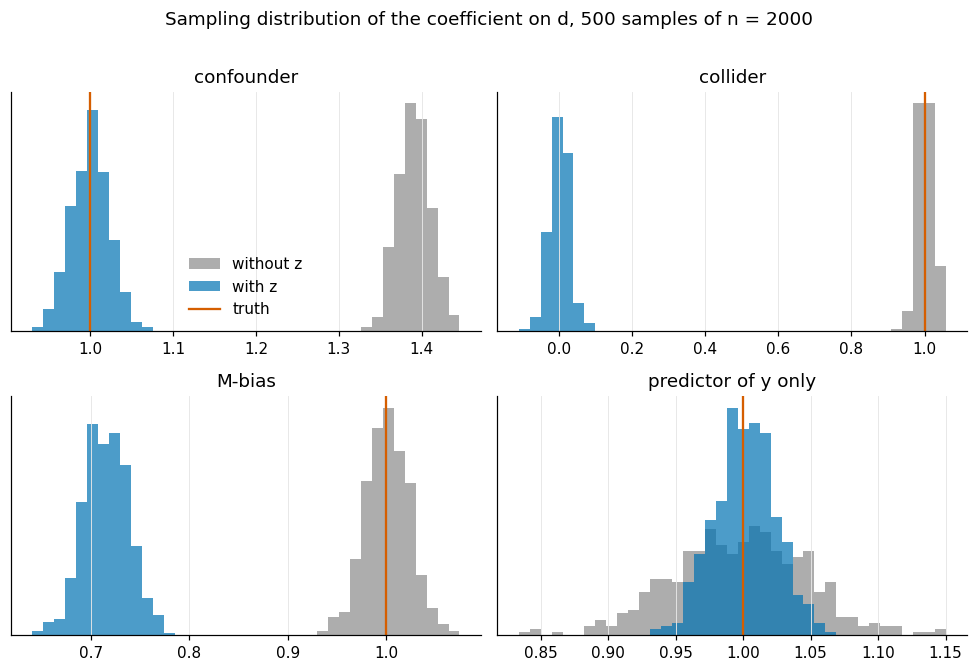

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6), sharex=False)
for ax, w in zip(axes.ravel(), ["confounder", "collider", "M-bias", "predictor of y only"]):
    bs, bl = draws[w]
    lo, hi = min(bs.min(), bl.min()), max(bs.max(), bl.max())
    bins = np.linspace(lo, hi, 40)
    ax.hist(bs, bins=bins, color=GREY, alpha=0.8, label="without z")
    ax.hist(bl, bins=bins, color=BLUE, alpha=0.7, label="with z")
    ax.axvline(1.0, color=VERMILLION, lw=1.5, label="truth")
    ax.set_title(w); ax.set_yticks([])
axes[0, 0].legend(frameon=False)
fig.suptitle("Sampling distribution of the coefficient on d, 500 samples of n = 2000", y=1.01)
plt.tight_layout(); plt.show()

The four panels are the four things conditioning can do: fix a bias
(confounder), create one (collider), create one with a variable that looks
like a confounder (M-bias), and buy precision without touching the mean
(predictor of $y$).

## 3. Coefficient movement is not a diagnostic

A common referee argument runs: "the coefficient is stable when controls
are added, so confounding is not a worry" — or its mirror image, "the
coefficient moved a lot, so the control matters and belongs in". The table
below collects what the simulation says about that logic.

In [5]:
diag = results[["beta without z", "beta with z"]].copy()
diag["moved?"] = np.where(np.abs(diag["beta with z"] - diag["beta without z"]) > 0.05, "yes", "no")   # 0.05 = about two SEs
diag["with z is right?"] = np.where(np.abs(diag["beta with z"] - 1.0) < 0.05, "yes", "no")
diag["verdict"] = ["good", "bad (total effect)", "bad", "bad", "bad", "bad", "bad", "neutral, more precise", "neutral, less precise"]
diag

,beta without z,beta with z,moved?,with z is right?,verdict
world,,,,,
confounder,1.390,1.000,yes,yes,good
mediator,1.000,0.600,yes,no,bad (total effect)
collider,1.002,0.001,yes,no,bad
weak collider,1.000,0.980,no,yes,bad
descendant of y,0.999,0.499,yes,no,bad
M-bias,1.001,0.715,yes,no,bad
bias amplifier,1.286,1.801,yes,no,bad
predictor of y only,0.998,1.001,no,yes,"neutral, more precise"
predictor of d only,1.000,0.999,no,yes,"neutral, less precise"


The column "moved?" does not predict the column "with $z$ is right?":

- moved **and** right: confounder (the movement was a correction);
- moved **and** wrong: mediator, collider, descendant of $y$, M-bias, bias
  amplifier (the movement was a change of estimand or a bias manufactured);
- did not move **and** wrong: weak collider (a quiet bad control);
- did not move **and** right: the two neutral controls.

Every cell of the 2 × 2 is occupied. Movement of the coefficient is not
evidence for or against the legitimacy of the control. The structural
question — does conditioning on $z$ recover the causal effect? — is
answered by the diagram, and only by the diagram. Stability is not
identification.

## 4. When do you need a control at all?

Cunningham's point: a variable matters for identification only if it is a
determinant of the missing counterfactual ($Y^0$, the untreated outcome)
**and** it is associated with treatment in the population — otherwise it is
not on a backdoor path. A cause of $y$ that is independent of treatment
does no harm when omitted; that is why an RCT needs no controls although
innumerable things cause the outcome (randomization makes every covariate
independent of $d$ by design; a realized sample still shows chance
imbalance, which is noise, not confounding). A variable that is associated
with treatment but does not cause $y$ is not a confounder either. Four
cases, binary treatment, true effect 1:

In [6]:
def case(drives_y, imbalanced, n=4000, reps=300, rng=rng):
    gamma = 2.0 if drives_y else 0.0
    bs, bl, ss, sl = [], [], [], []
    for _ in range(reps):
        z = rng.normal(size=n)
        p = 1 / (1 + np.exp(-1.5 * z)) if imbalanced else np.full(n, 0.5)
        d = rng.binomial(1, p)
        y = 1.0 * d + gamma * z + rng.normal(size=n)
        df = pd.DataFrame({"y": y, "d": d, "z": z})
        s = sm.OLS(df["y"], sm.add_constant(df[["d"]])).fit()
        l = sm.OLS(df["y"], sm.add_constant(df[["d", "z"]])).fit()
        bs.append(s.params["d"]); bl.append(l.params["d"]); ss.append(s.bse["d"]); sl.append(l.bse["d"])
    return {"z drives y": drives_y, "z imbalanced": imbalanced,
            "beta without z": np.mean(bs), "beta with z": np.mean(bl),
            "SE without z": np.mean(ss), "SE with z": np.mean(sl)}

pd.DataFrame([case(a, b) for a in (True, False) for b in (True, False)]).set_index(["z drives y", "z imbalanced"])

beta without z  beta with z  SE without z  SE with z
z drives y z imbalanced                                                      
True       True                   3.120        0.999         0.062      0.037
           False                  1.004        1.000         0.071      0.032
False      True                   1.000        1.000         0.032      0.037
           False                  1.002        1.002         0.032      0.032

Only the first row has a problem that the control fixes. In the second row
($z$ drives $y$, independent of $d$ — the RCT case) the control is optional:
it buys precision, it does not remove bias. In rows three and four it is
irrelevant. Three separate things are usually lumped together as
"balance": identification (is $z$ on a backdoor path — a population
question, settled by the causal model), realized imbalance in a finite
sample (noise, not confounding, when assignment was random), and precision.
The adjustment set comes from the first; balance diagnostics check the
design, they are not a keep/drop rule. And every control adds reliance on
functional form in OLS (the exogeneity bundle of Set 1) and thins the
support for matching or flexible conditioning.

## 5. Gelbach's decomposition: which control moves the estimate?

Suppose the DAG says $z_1, z_2, z_3$ are confounders and the paper reports
a base specification ($y$ on $d$) and a full one ($y$ on $d$ and all three).
The estimate moved. Which control is responsible? The usual answer — add
the controls one at a time and watch — depends on the order. Gelbach (2016)
shows that the omitted-variable-bias formula gives an exact, order-free
answer:

$$\hat\beta_{\text{base}} - \hat\beta_{\text{full}} = \sum_k \hat\lambda_k\, \hat\gamma_k ,$$

where $\hat\gamma_k$ is the coefficient on $z_k$ in the full regression and
$\hat\lambda_k$ is the slope of $z_k$ on $d$ (the auxiliary regression). The
identity holds in the sample, exactly, by the algebra of OLS. We build a
case with one strong confounder, one weak confounder and one balanced
predictor of $y$:

In [7]:
n = 5000
d  = rng.normal(size=n)
z1 = 0.9 * d + rng.normal(size=n)          # strong confounder (for the decomposition read z1 -> d, z1 -> y)
z2 = 0.3 * d + rng.normal(size=n)          # weak confounder
z3 = rng.normal(size=n)                    # predictor of y, balanced
y  = 1.0 * d + 1.0 * z1 + 1.0 * z2 + 1.5 * z3 + rng.normal(size=n)
g = pd.DataFrame({"y": y, "d": d, "z1": z1, "z2": z2, "z3": z3})

base = ols("y ~ d", g)
full = ols("y ~ d + z1 + z2 + z3", g)
gap = base.params["d"] - full.params["d"]

rows = []
for k in ["z1", "z2", "z3"]:
    lam = ols(f"{k} ~ d", g).params["d"]        # auxiliary regression
    gam = full.params[k]
    rows.append({"control": k, "lambda (z_k on d)": lam, "gamma (full model)": gam, "delta_k = lambda*gamma": lam * gam})
dec = pd.DataFrame(rows).set_index("control")
dec.loc["sum"] = ["", "", dec["delta_k = lambda*gamma"].sum()]
print(f"beta_base = {base.params['d']:.4f}   beta_full = {full.params['d']:.4f}   gap = {gap:.4f}")
dec

beta_base = 2.2175   beta_full = 0.9999   gap = 1.2177


,lambda (z_k on d),gamma (full model),delta_k = lambda*gamma
control,,,
z1,0.915,1.006,0.920
z2,0.322,1.014,0.327
z3,-0.020,1.501,-0.029
sum,,,1.218


The three $\delta_k$ add up to the gap exactly; $z_1$ accounts for most of
it, $z_2$ for a little, and the balanced $z_3$ for nothing — although it is
the variable with the largest coefficient in the full model. A large
$\gamma_k$ is not enough; it takes $\lambda_k \neq 0$ as well, which is the
imbalance condition of Section 4 in regression form.

For contrast, the sequential approach in two orders:

In [8]:
def sequential(order):
    prev = base.params["d"]; out = {}
    for i in range(1, len(order) + 1):
        f = ols("y ~ d + " + " + ".join(order[:i]), g)
        out[order[i - 1]] = prev - f.params["d"]; prev = f.params["d"]
    return pd.Series(out)

pd.DataFrame({"order z1,z2,z3": sequential(["z1", "z2", "z3"]),
              "order z3,z2,z1": sequential(["z3", "z2", "z1"]).reindex(["z1", "z2", "z3"]),
              "Gelbach": dec["delta_k = lambda*gamma"].iloc[:3]})

,"order z1,z2,z3","order z3,z2,z1",Gelbach
z1,0.900,0.924,0.920
z2,0.351,0.323,0.327
z3,-0.033,-0.030,-0.029


Here the controls are nearly uncorrelated with each other, so the orders
agree closely; with correlated controls the sequential attributions can
differ by a lot while the Gelbach shares stay put. Either way the
decomposition answers the statistical question — which observed control
moves the estimate — and presupposes that the controls are legitimate.

## 6. Oster's $\delta$: how much unobserved selection would it take?

Oster (2019) turns coefficient movement into a bounded statement about
*unobserved* confounding, under the assumption that selection on
unobservables is proportional to selection on observables. With
$\hat\beta_{\text{base}}, R_{\text{base}}$ from the short regression,
$\hat\beta_{\text{full}}, R_{\text{full}}$ from the long one, and a maximal
$R_{\max}$ the outcome could reach, the simplified version of her estimator
is

$$\beta^* \approx \hat\beta_{\text{full}} - \delta\,
\big(\hat\beta_{\text{base}} - \hat\beta_{\text{full}}\big)\,
\frac{R_{\max} - R_{\text{full}}}{R_{\text{full}} - R_{\text{base}}},$$

and solving $\beta^* = 0$ for $\delta$ gives how many times stronger than
the observed selection the unobserved selection would have to be to
explain the whole effect — *given* $R_{\max}$, the control set, the linear
model and the proportional-selection assumption. $\delta > 1$ is a
benchmark, not a proof. (This is the restricted formula; the full estimator
in the paper is a cubic — Stata `psacalc`, R `robomit`.) Applied to the Gelbach example
with $R_{\max} = 1.3\,R_{\text{full}}$, Oster's suggested rule of thumb:

In [9]:
def oster(base, full, d="d", r_max=None, delta=1.0):
    bb, bf = base.params[d], full.params[d]
    rb, rf = base.rsquared, full.rsquared
    r_max = min(1.0, 1.3 * rf) if r_max is None else r_max
    beta_star = bf - delta * (bb - bf) * (r_max - rf) / (rf - rb)
    delta_zero = bf * (rf - rb) / ((bb - bf) * (r_max - rf))
    return pd.Series({"beta_base": bb, "beta_full": bf, "R2_base": rb, "R2_full": rf, "R_max": r_max,
                      "beta* (delta=1)": beta_star, "delta for beta*=0": delta_zero})

oster(base, full)

beta_base           2.218
beta_full           1.000
R2_base             0.488
R2_full             0.902
R_max               1.000
beta* (delta=1)     0.713
delta for beta*=0   3.483
dtype: float64

With a true effect of 1, $\beta^*$ at $\delta = 1$ stays well away from
zero and the $\delta$ needed to kill the effect is far above 1 — as it
should be, because in this world there *is* no unobserved confounder. The
calculation is only as good as its premises: proportional selection, a
sensible $R_{\max}$, and — once more — that the observed controls are
confounders rather than mediators or colliders. Both Gelbach and Oster
quantify something about the controls you chose; neither can tell you
whether you chose them well.

## Summary

- Controlling for $z$ = using the residual of $d$ on $z$. The mechanism is
  the same for every $z$; the consequence depends on the DAG.
- Nine worlds, true effect 1: one good control, six bad ones, two neutral.
  The regression output looks alike across them.
- Coefficient movement separates nothing: good and bad controls both move
  the estimate, and a weak collider does not.
- For identification a determinant of $Y^0$ matters only if it is
  associated with treatment in the population; an RCT needs no controls,
  though balanced predictors of $y$ buy precision.
- Gelbach: exact, order-free attribution of the base–full gap to each
  control. Oster: how strong unobserved selection would have to be. Both
  answer the statistical question; the structural one comes from the
  diagram.